In [37]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten

In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
path = "/content/drive/MyDrive/Image Classification CNN Keras Dataset/"

X_train = np.loadtxt(path + "input.csv", delimiter=',')
Y_train = np.loadtxt(path + "labels.csv", delimiter=',')

X_test = np.loadtxt(path + "input_test.csv", delimiter=',')
Y_test = np.loadtxt(path + "labels_test.csv", delimiter=',')

In [40]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train/255.0
X_test = X_test/255.0

In [41]:
print("Shape of X_train: ", X_train.shape)
print("Shape of Y_train: ", Y_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of Y_test: ", Y_test.shape)

Shape of X_train:  (2000, 100, 100, 3)
Shape of Y_train:  (2000, 1)
Shape of X_test:  (400, 100, 100, 3)
Shape of Y_test:  (400, 1)


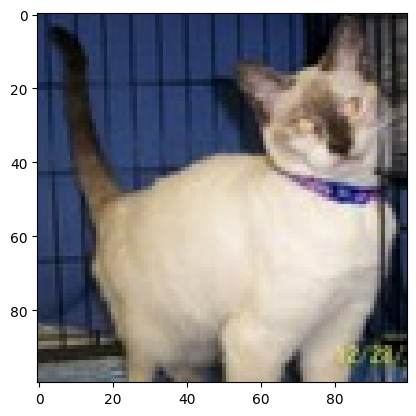

In [42]:
idx = random.randrange(len(X_train))
plt.imshow(X_train[idx, :])
plt.show()

In [43]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation = 'relu', input_shape = (100, 100, 3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(32, (3,3), activation = 'relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(64, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [44]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [45]:
model.fit(X_train, Y_train, epochs = 5, batch_size = 64)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 672ms/step - accuracy: 0.5200 - loss: 0.7207
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 42s 711ms/step - accuracy: 0.5625 - loss: 0.6769
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 933ms/step - accuracy: 0.6315 - loss: 0.6386
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 743ms/step - accuracy: 0.6900 - loss: 0.5825
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 696ms/step - accuracy: 0.7385 - loss: 0.5324


In [46]:
model.evaluate(X_test, Y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 150ms/step - accuracy: 0.6700 - loss: 0.5957


[0.5956951379776001, 0.6700000166893005]

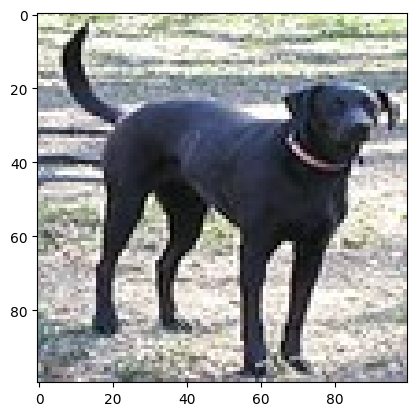

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Our model says it is: Dog


In [57]:
idx2 = random.randrange(len(Y_test))
plt.imshow(X_test[idx2, :])
plt.show()

y_pred = model.predict(
    X_test[idx2].reshape(1, 100, 100, 3)
)

if y_pred[0][0] >= 0.5:
    pred = "Cat"
else:
    pred = "Dog"

print("Our model says it is:", pred)